In [1]:
using DynamicEnergy.ChilledWater: WaterPort, Boundary_pT, MixingVolume, PressureDrop, Pump_dp

In [2]:
using ModelingToolkit: equations, observed, mtkcompile, @named, connect, System
using ModelingToolkit: t_nounits as t

settings = (
    inlet_T = 313.15, initial_T = 293.15, volume = 1.0,
    density = 997.0, specific_heat = 4186.0,
    boundary_p = 101325.0, pump_dp = 100000.0,
    nominal_flow = 1.0, nominal_dp = 1000.0,
    tspan = (0.0, 600.0), reltol = 1e-8, abstol = 1e-8, dtmax = 2.0,
)
@named Source = Boundary_pT(p = settings.boundary_p, T = settings.inlet_T)
@named Sink = Boundary_pT(p = settings.boundary_p, T = settings.initial_T)
@named Pump = Pump_dp(dp = settings.pump_dp)
@named Pipe = PressureDrop(nominalFlowRate = settings.nominal_flow,
    nominalPressureDrop = settings.nominal_dp)
@named Tank = MixingVolume(volume = settings.volume, T_init = settings.initial_T)
connections = [
    connect(Source.port, Pump.port1),
    connect(Pump.port2, Pipe.port1),
    connect(Pipe.port2, Tank.port_1),
    connect(Tank.port_2, Sink.port),
]
@named raw_model = System(connections, t, [], [];
    systems = [Source, Sink, Pump, Pipe, Tank])
sys = mtkcompile(raw_model)
display(sys)
println("\nEquations:")
foreach(println, equations(sys))
println("\nObserved:",)
foreach(println, observed(sys))


Model raw_model:
Equations (2):
  2 standard: see equations(raw_model)
Unknowns (2): see unknowns(raw_model)
  Pipe₊port1₊mFlow(t)
  Tank₊T(t)
Observed (23): see observed(raw_model)


Equations:
0 ~ -Pipe₊port1₊p(t) + Pipe₊port2₊p(t) + 1000.0Pipe₊port1₊mFlow(t)*abs(Pipe₊port1₊mFlow(t))
Differential(t, 1)(Tank₊T(t)) ~ (Pipe₊port1₊mFlow(t)*ifelse(0 < (-Pipe₊port1₊mFlow(t)), Sink₊port₊h_outflow(t), 4186.0(-273.15 + Tank₊T(t))) - Pipe₊port1₊mFlow(t)*ifelse(0 < Pipe₊port1₊mFlow(t), Pipe₊port2₊h_outflow(t), 4186.0(-273.15 + Tank₊T(t)))) / -4.173442e6

Observed:
Sink₊port₊h_outflow(t) ~ 83720.0
Pump₊port1₊p(t) ~ 101325.0
Pipe₊port2₊p(t) ~ 101325.0
Pipe₊port2₊h_outflow(t) ~ 167440.0
Pipe₊port2₊mFlow(t) ~ -Pipe₊port1₊mFlow(t)
Pump₊port2₊mFlow(t) ~ -Pipe₊port1₊mFlow(t)
Tank₊port_1₊mFlow(t) ~ Pipe₊port1₊mFlow(t)
Pump₊port1₊mFlow(t) ~ Pipe₊port1₊mFlow(t)
Source₊port₊mFlow(t) ~ -Pipe₊port1₊mFlow(t)
Sink₊port₊mFlow(t) ~ Pipe₊port1₊mFlow(t)
Tank₊port_2₊mFlow(t) ~ -Pipe₊port1₊mFlow(t)
Pipe₊port1₊h_outflow(t) ~ 4186.0(-273.15 + Tank₊T(t))
Tank₊port_2₊h_outflow(t) ~ 4186.0(-273.15 + Tank₊T(t))
Pipe₊port1₊p(t) ~ 100000.0 + Pump₊port1₊p(t)
Source₊port₊p(t) ~ Pump₊port1₊p(t)
Tank₊port_

In [3]:
using ModelingToolkit: ODEProblem, solve
using DifferentialEquations
prob = ODEProblem(sys, [], settings.tspan)
display(prob)
display(prob.f.mass_matrix)
# sol = solve(
#     prob,
#     Rodas5P();
#     abstol = 1e-9,
#     reltol = 1e-8
# )
sol = solve(prob)

ODEProblem with uType Vector{Float64} and tType Float64. In-place: true
Initialization status: FULLY_DETERMINED
Non-trivial mass matrix: true
timespan: (0.0, 600.0)
u0: 2-element Vector{Float64}:
   1.0
 293.15

2×2 LinearAlgebra.Diagonal{Float64, Vector{Float64}}:
 0.0   ⋅ 
  ⋅   1.0

retcode: Success
Interpolation: 3rd order Hermite
t: 13-element Vector{Float64}:
   0.0
   1.0e-6
   0.0004425974474063406
   0.004858571921469746
   0.049018316662103795
   0.4906157640684442
   4.906590238131848
  39.39763701076945
 103.90135638752227
 187.07470408526632
 298.4336167024048
 444.1637917637202
 600.0
u: 13-element Vector{Vector{Float64}}:
 [10.0, 293.15]
 [10.0, 293.1500002006017]
 [10.0, 293.1500887856498]
 [10.0, 293.15097461455144]
 [10.0, 293.1598307459396]
 [10.0, 293.24817665018134]
 [10.0, 294.1104436043569]
 [10.0, 299.6785797649287]
 [10.0, 306.0960164613526]
 [10.0, 310.0871152101617]
 [10.0, 312.1475758404998]
 [10.0, 312.9175915030829]
 [10.0, 313.1013112229457]

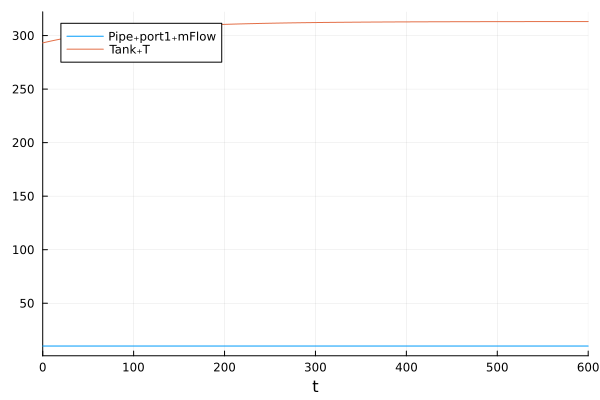

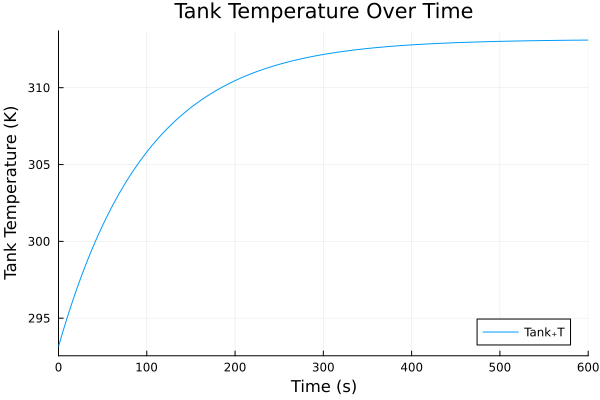

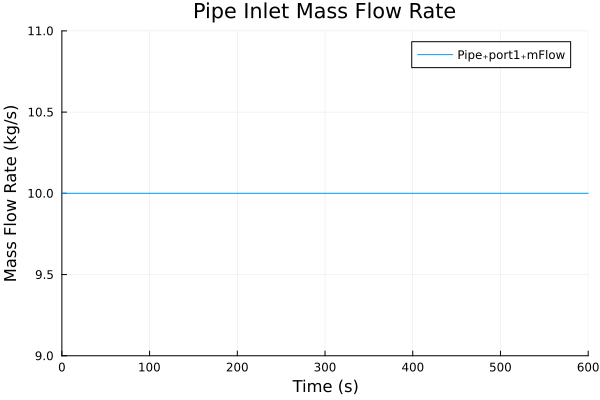

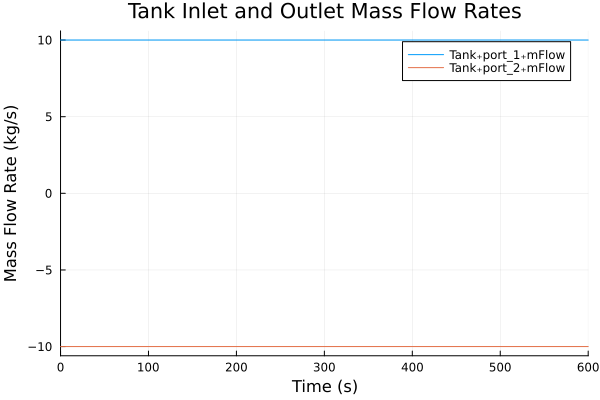

┌ Warning: To maintain consistency with solution indexing, keyword argument vars will be removed in a future version. Please use keyword argument idxs instead.
│   caller = ip:0x0
└ @ Core :-1


In [4]:
using Plots: plot
display(plot(sol))
display(plot(sol; vars = [Tank.T], xlabel = "Time (s)", ylabel = "Tank Temperature (K)", title = "Tank Temperature Over Time"))
display(plot(sol; vars = [Pipe.port1.mFlow], xlabel = "Time (s)", ylabel = "Mass Flow Rate (kg/s)", title = "Pipe Inlet Mass Flow Rate", ylims = (9.0, 11.0)))
display(plot(sol; vars = [Tank.port_1.mFlow, Tank.port_2.mFlow], xlabel = "Time (s)", ylabel = "Mass Flow Rate (kg/s)", title = "Tank Inlet and Outlet Mass Flow Rates"))

In [5]:
ts = collect(0.0:10.0:600.0)

vars = [Tank.T, Pipe.port1.mFlow, Tank.port_1.mFlow, Tank.port_2.mFlow]

data = hcat([sol(t; idxs = vars) for t in ts]...)
display(data)
data = permutedims(data)
display(data)
data_with_time = hcat(ts, data)
display(data_with_time)

column_name = ["Time (s)", "Tank Temperature (K)", "Pipe Inlet Mass Flow Rate (kg/s)", "Tank Inlet Mass Flow Rate (kg/s)", "Tank Outlet Mass Flow Rate (kg/s)"]

using DataFrames
df = DataFrame(data_with_time, Symbol.(column_name))
display(df)

4×61 Matrix{Float64}:
 293.15  295.059  296.785  298.347  …  313.084  313.09  313.096  313.101
  10.0    10.0     10.0     10.0        10.0     10.0    10.0     10.0
  10.0    10.0     10.0     10.0        10.0     10.0    10.0     10.0
 -10.0   -10.0    -10.0    -10.0       -10.0    -10.0   -10.0    -10.0

61×4 Matrix{Float64}:
 293.15   10.0  10.0  -10.0
 295.059  10.0  10.0  -10.0
 296.785  10.0  10.0  -10.0
 298.347  10.0  10.0  -10.0
 299.76   10.0  10.0  -10.0
 301.038  10.0  10.0  -10.0
 302.194  10.0  10.0  -10.0
 303.239  10.0  10.0  -10.0
 304.185  10.0  10.0  -10.0
 305.041  10.0  10.0  -10.0
   ⋮                  
 313.041  10.0  10.0  -10.0
 313.052  10.0  10.0  -10.0
 313.061  10.0  10.0  -10.0
 313.07   10.0  10.0  -10.0
 313.077  10.0  10.0  -10.0
 313.084  10.0  10.0  -10.0
 313.09   10.0  10.0  -10.0
 313.096  10.0  10.0  -10.0
 313.101  10.0  10.0  -10.0

61×5 Matrix{Float64}:
   0.0  293.15   10.0  10.0  -10.0
  10.0  295.059  10.0  10.0  -10.0
  20.0  296.785  10.0  10.0  -10.0
  30.0  298.347  10.0  10.0  -10.0
  40.0  299.76   10.0  10.0  -10.0
  50.0  301.038  10.0  10.0  -10.0
  60.0  302.194  10.0  10.0  -10.0
  70.0  303.239  10.0  10.0  -10.0
  80.0  304.185  10.0  10.0  -10.0
  90.0  305.041  10.0  10.0  -10.0
   ⋮                         
 520.0  313.041  10.0  10.0  -10.0
 530.0  313.052  10.0  10.0  -10.0
 540.0  313.061  10.0  10.0  -10.0
 550.0  313.07   10.0  10.0  -10.0
 560.0  313.077  10.0  10.0  -10.0
 570.0  313.084  10.0  10.0  -10.0
 580.0  313.09   10.0  10.0  -10.0
 590.0  313.096  10.0  10.0  -10.0
 600.0  313.101  10.0  10.0  -10.0

Row,Time (s),Tank Temperature (K),Pipe Inlet Mass Flow Rate (kg/s),Tank Inlet Mass Flow Rate (kg/s),Tank Outlet Mass Flow Rate (kg/s)
,Float64,Float64,Float64,Float64,Float64
1,0.0,293.15,10.0,10.0,-10.0
2,10.0,295.059,10.0,10.0,-10.0
3,20.0,296.785,10.0,10.0,-10.0
4,30.0,298.347,10.0,10.0,-10.0
5,40.0,299.76,10.0,10.0,-10.0
6,50.0,301.038,10.0,10.0,-10.0
7,60.0,302.194,10.0,10.0,-10.0
8,70.0,303.239,10.0,10.0,-10.0
9,80.0,304.185,10.0,10.0,-10.0
